# Exploratory Data Analysis: Saskatchewan Public-Sector Jobs

What the scraped postings look like: who is hiring, for what, where, at what pay, and how postings behave over time.

| Section | Question |
|---|---|
| 1. Load | Which files, how many postings per employer |
| 2. Data coverage | Which fields each employer actually fills |
| 3. Preparation | Dates, job families, union labels, salary units |
| 4. Composition | Employers, job families, cities, employment types, unions |
| 5. Salary | Pay distribution, by employer and job family |
| 6. Time | Posting age, application windows, posting dates |
| 7. SHA vs other employers | How different the two groups are |
| 8. Key findings | Summary for the report |

**Scope.** This notebook only *reads* the scraper's CSVs; it never changes them. Detailed data-quality rules
(Q1-Q7), city spelling review and duplicate/repost checks live in `sk_jobs_profiling.ipynb`; they are not repeated here.

**Run it** from the `sk-jobs-pipeline` folder (VS Code, Jupyter or Colab) with *Restart & Run All*. No credentials needed.

## 0. Setup

In [1]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", message=".*vert: bool.*")   # boxplot(vert=False) still works on every matplotlib version

DATA_DIR = Path("data")
HOURS_PER_YEAR = 2080            # 40 h x 52 weeks, used to compare hourly / monthly / annual pay
SHA = "Saskatchewan Health Authority"

# Chart style: one accent colour for single-series charts, a second for comparisons.
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titlecolor": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
})


def barh(values: pd.Series, title: str, xlabel: str = "Postings", pct: bool = False, color=BLUE, ax=None):
    # Horizontal bars, largest at the top, value printed at the end of each bar.
    values = values.sort_values()
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 0.34 * len(values) + 1.2))
    ax.barh(values.index.astype(str), values.values, color=color, height=0.65)
    for y, v in enumerate(values.values):
        ax.text(v, y, f" {v:.0f}%" if pct else f" {v:,.0f}", va="center", fontsize=9, color=MUTED)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.12)
    return ax


dollars = FuncFormatter(lambda v, _: f"${v:,.0f}")

ModuleNotFoundError: No module named 'numpy'

## 1. Load
The newest `saskatchewan_public_sector_jobs_master_<date>.csv` holds every posting **listed on the collection day** (all open).
`past_postings_master.csv` holds postings that have since **closed**. SaskWater's postings are currently only in that file,
so leaving it out would drop an employer. The two files never share a `Record_ID`, but duplicates are dropped anyway.

In [ ]:
masters = sorted(DATA_DIR.glob("saskatchewan_public_sector_jobs_master_*.csv"))
if not masters:
    raise FileNotFoundError(f"No master CSV in {DATA_DIR.resolve()} - run this notebook from sk-jobs-pipeline/")
current_file = masters[-1]

current = pd.read_csv(current_file).assign(Status="Open")
past_file = DATA_DIR / "past_postings_master.csv"
past = pd.read_csv(past_file).assign(Status="Closed") if past_file.exists() else pd.DataFrame()

df = (pd.concat([current, past], ignore_index=True)
        .drop_duplicates(subset=["Source", "Record_ID"], keep="first")
        .replace(r"^\s*$", np.nan, regex=True))

print(f"Current file: {current_file.name}  ({len(current):,} rows)")
print(f"Past file:    {past_file.name}  ({len(past):,} rows)")
print(f"Combined:     {len(df):,} postings x {df.shape[1]} columns\n")

counts = (df.pivot_table(index="Source", columns="Status", values="Record_ID", aggfunc="count", fill_value=0)
            .assign(Total=lambda t: t.sum(axis=1))
            .sort_values("Total", ascending=False))
counts["Share_%"] = (counts["Total"] / counts["Total"].sum() * 100).round(1)
counts

Current file: saskatchewan_public_sector_jobs_master_2026-10-10.csv  (2,308 rows)
Past file:    past_postings_master.csv  (52 rows)
Combined:     2,360 postings x 34 columns



Status,Closed,Open,Total,Share_%
Source,,,,
Saskatchewan Health Authority,0,2156,2156,91.4
Government of Saskatchewan,0,122,122,5.2
SaskWater,52,0,52,2.2
SaskTel,0,14,14,0.6
SaskPower,0,11,11,0.5
SaskEnergy,0,5,5,0.2


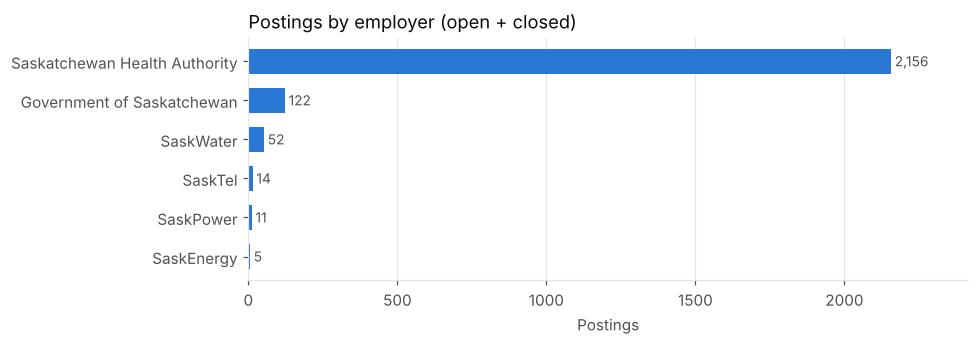

In [ ]:
ax = barh(counts["Total"], "Postings by employer (open + closed)")
plt.tight_layout(); plt.show()

## 2. Data coverage
Share of postings where each analysis field is filled, per employer. A field an employer never fills (0%) usually means
its site doesn't publish it, not a scraper bug, but it limits which comparisons are fair.

`Job_ID` is only unique **within** an employer (GoS and SHA both use plain numbers), so the ID check below groups by `Source`.

In [ ]:
FIELDS = ["Job_Title", "Category", "Job_Function", "City", "Employment_Type_Standardized", "FTE", "Union",
          "Salary_Min", "Salary_Unit", "Posting_Date", "Closing_Date", "Number_of_Openings",
          "Description", "Qualifications", "Responsibilities"]
coverage = (df[FIELDS].notna().groupby(df["Source"]).mean().mul(100).round(0)
              .T.reindex(columns=counts.index))
coverage["All"] = df[FIELDS].notna().mean().mul(100).round(0)
display(coverage.style.format("{:.0f}%").background_gradient(cmap="Blues", vmin=0, vmax=100))

dup_ids = df.duplicated(subset=["Source", "Job_ID"], keep=False) & df["Job_ID"].notna()
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print(f"Repeated Job_ID within the same employer: {dup_ids.sum()}")
print(f"Same Job_ID at two different employers (not a duplicate): "
      f"{df.dropna(subset=['Job_ID']).groupby('Job_ID')['Source'].nunique().gt(1).sum()}")

Source,Saskatchewan Health Authority,Government of Saskatchewan,SaskWater,SaskTel,SaskPower,SaskEnergy,All
Job_Title,100%,100%,100%,100%,100%,100%,100%
Category,99%,100%,13%,100%,91%,40%,97%
Job_Function,99%,100%,13%,0%,0%,0%,96%
City,100%,100%,98%,93%,100%,100%,100%
Employment_Type_Standardized,100%,100%,13%,93%,100%,100%,98%
FTE,99%,0%,0%,0%,0%,0%,90%
Union,100%,0%,0%,0%,55%,100%,92%
Salary_Min,99%,100%,100%,93%,36%,100%,99%
Salary_Unit,99%,100%,100%,93%,36%,100%,99%
Posting_Date,100%,100%,100%,100%,100%,100%,100%


Exact duplicate rows: 0
Repeated Job_ID within the same employer: 0
Same Job_ID at two different employers (not a duplicate): 1


## 3. Preparation
Derived columns used below. Raw columns are kept unchanged.

- **Dates** parsed to `datetime`.
- **`Job_Family`**: one cross-employer grouping. Every employer names its categories differently (SHA *Nursing*,
  GoS *Human Services*, SaskTel *Business Sales*), and the crown corporations leave `Job_Function` blank.
  The keyword rules are the same ones as in `sk_jobs_profiling.ipynb`, applied to `Job_Function` first, then `Category`, then the title.
  `Job_Function` goes first because SHA's category *Community Care* would otherwise match the "community" rule and send
  324 nursing postings to Education & Social Services. Titles containing *Technologist* (SaskWater) go to Engineering, not IT.
- **`Union_Clean`**: merges spelling variants of the same union.
- **Salary unit**: see 3.1.

In [ ]:
for col in ["Posting_Date", "Closing_Date", "Collection_Date", "First_Seen_Date", "Last_Seen_Date", "Closed_Detected_Date"]:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col].astype("string").str[:10], errors="coerce")

# Same rules as sk_jobs_profiling.ipynb (section 5) - keep the two in sync.
JOB_FAMILY_RULES = [
    ("Healthcare", r"nurs|health|medical|clinic|care aide|continuing care|pharm|therap|lab(oratory)?\b|diagnos|imaging|mental|patient|physician|dietary|dental"),
    ("IT & Data", r"information tech|\bit\b|technolog|software|digital|data|cyber|systems|network|telecom"),
    ("Engineering", r"engineer|technical|technolog(ist|y services)|design|drafting|scien"),
    ("Trades & Operations", r"trade|electric|mechanic|operator|operations|maintenance|construction|apprentic|journeyperson|power line|plant|field|equipment|facilit|labour"),
    ("Finance & Accounting", r"financ|account|audit|budget|payroll|tax|actuar|revenue|economic"),
    ("Customer Service & Sales", r"customer|sales|retail|call cent|contact cent|client serv|store|marketing"),
    ("Education & Social Services", r"educat|teach|learning|social|child|family|community|youth|correction|justice|probation|counsel"),
    ("Policy, Legal & Government", r"policy|legal|law|regulat|compliance|government|program|legislat|research|planning|analyst"),
    ("HR & Communications", r"human res|\bhr\b|talent|recruit|communicat|public affairs|media"),
    ("Administration", r"admin|clerical|office|reception|secretar|records|support services"),
    ("Management & Executive", r"manage|director|executive|leadership|supervis"),
    ("Students & Talent Pools", r"student|intern|co-?op|summer|talent pool|future opportunit"),
]
# SHA's own function labels that the keyword rules would misplace
FUNCTION_OVERRIDES = {
    "Professional": "Healthcare", "Clinical Professional": "Healthcare",
    "Technologists and Technicians": "Healthcare", "Support Worker": "Healthcare",
    "Human Services": "Education & Social Services",
}


TITLE_OVERRIDES = [("Engineering", r"technologist")]


def job_family(row) -> str:
    if row.get("Job_Function") in FUNCTION_OVERRIDES:
        return FUNCTION_OVERRIDES[row["Job_Function"]]
    if pd.isna(row.get("Job_Function")) and pd.isna(row.get("Category")):
        for family, pattern in TITLE_OVERRIDES:
            if re.search(pattern, str(row.get("Job_Title")), re.I):
                return family
    for field in ["Job_Function", "Category", "Job_Title"]:
        text = row.get(field)
        if pd.isna(text):
            continue
        for family, pattern in JOB_FAMILY_RULES:
            if re.search(pattern, str(text), re.I):
                return family
    return "Other"


df["Job_Family"] = df.apply(job_family, axis=1)


def clean_union(u):
    if pd.isna(u):
        return np.nan
    s = str(u).lower()
    for key, name in [("sgeu", "SGEU"), ("cupe", "CUPE"), ("canadian union of public", "CUPE"),
                      ("ibew", "IBEW"), ("unifor", "Unifor"), ("out of scope", "Out of scope"),
                      (r"\boos\b", "Out of scope"), ("non-union", "Non-union"), ("non union", "Non-union")]:
        if re.search(key, s):
            return name
    return str(u).strip()


df["Union_Clean"] = df["Union"].map(clean_union)

print("Postings per job family:")
display(pd.crosstab(df["Job_Family"], df["Source"], margins=True, margins_name="Total")
          .sort_values("Total", ascending=False))

Postings per job family:


Source,Government of Saskatchewan,SaskEnergy,SaskPower,SaskTel,SaskWater,Saskatchewan Health Authority,Total
Job_Family,,,,,,,
Total,122,5,11,14,52,2156,2360
Healthcare,2,0,0,0,0,2015,2017
Trades & Operations,15,3,5,0,7,73,103
Administration,22,0,0,1,0,56,79
Education & Social Services,37,0,0,0,0,0,37
Engineering,0,1,1,0,26,2,30
"Policy, Legal & Government",21,0,0,0,1,0,22
Management & Executive,3,0,0,0,5,7,15
Customer Service & Sales,2,0,1,8,3,0,14


### 3.1 Salary unit
Salary columns come as a min/max plus a unit, and the unit is often a guess:

| `Salary_Unit` from the scraper | Meaning |
|---|---|
| `Hourly`, `Monthly`, `Annual` | stated on the posting |
| `Hourly (inferred)`, `Annual (inferred)` | the scraper guessed from the size of the number |
| blank / `Unspecified` | no usable unit |

Each posting gets a **`Final_Unit`** and a **`Unit_Source`**:

1. Take the scraper's unit (stated or inferred).
2. Check the midpoint fits that unit's plausible range: hourly $10-$200, monthly $1,000-$35,000, annual $15,000-$500,000.
3. If there is no unit, or it fails the check, infer it from the size of the midpoint. Monthly and annual overlap
   between $15,000 and $35,000; values there stay **Unresolved** rather than guessed.

Then every posting is converted to an **hourly equivalent** (`Hourly_Equiv`, 2,080 h/year) so all employers share one scale.

In [ ]:
UNIT_RANGES = {"Hourly": (10, 200), "Monthly": (1_000, 35_000), "Annual": (15_000, 500_000)}
TO_HOURLY = {"Hourly": 1, "Monthly": 12 / HOURS_PER_YEAR, "Annual": 1 / HOURS_PER_YEAR}

df["Salary_Mid"] = (df["Salary_Min"] + df["Salary_Max"]) / 2


def fits(mid, unit) -> bool:
    lo, hi = UNIT_RANGES[unit]
    return lo <= mid <= hi


def unit_from_size(mid):
    matches = [u for u in UNIT_RANGES if fits(mid, u)]
    return matches[0] if len(matches) == 1 else None


def resolve_unit(row):
    mid, raw = row["Salary_Mid"], row["Salary_Unit"]
    if pd.isna(mid):
        return pd.Series([None, "No salary"])
    raw = "" if pd.isna(raw) else str(raw)
    base = re.match(r"(Hourly|Monthly|Annual)", raw)
    if base and fits(mid, base.group(1)):
        return pd.Series([base.group(1), "Scraper inferred" if "inferred" in raw.lower() else "Stated"])
    guess = unit_from_size(mid)
    return pd.Series([guess, "Size check" if guess else "Unresolved"])


df[["Final_Unit", "Unit_Source"]] = df.apply(resolve_unit, axis=1)
df["Hourly_Equiv"] = df["Salary_Mid"] * df["Final_Unit"].map(TO_HOURLY)

display(pd.crosstab([df["Unit_Source"]], df["Final_Unit"].fillna("-"), margins=True, margins_name="Total"))

changed = df[df["Unit_Source"].isin(["Size check", "Unresolved"]) & df["Salary_Mid"].notna()]
print("Rows the size check changed or could not resolve:")
display(changed[["Source", "Job_Title", "Salary_Range", "Salary_Unit", "Final_Unit", "Hourly_Equiv"]].round(2))

Final_Unit,-,Annual,Hourly,Monthly,Total
Unit_Source,,,,,
No salary,35,0,0,0,35
Scraper inferred,0,7,2260,0,2267
Size check,0,0,0,1,1
Stated,0,3,27,27,57
Total,35,10,2287,28,2360


Rows the size check changed or could not resolve:


,Source,Job_Title,Salary_Range,Salary_Unit,Final_Unit,Hourly_Equiv
2329,SaskWater,"Manager, Project Management & Procurement","$9,381 to $12,195 (Management Level 8)",Unspecified,Monthly,62.24


In [ ]:
# Sanity check: does the scraper's guessed hourly pay look like stated hourly pay?
display(df[df["Final_Unit"].eq("Hourly")].groupby("Unit_Source")["Hourly_Equiv"].describe().round(2))

,count,mean,std,min,25%,50%,75%,max
Unit_Source,,,,,,,,
Scraper inferred,2260.0,38.40,10.75,18.26,29.30,39.42,44.32,79.34
Stated,27.0,34.46,8.05,22.55,28.54,32.10,39.62,52.15


## 4. Composition
SHA posts the large majority of jobs, so each chart is shown **for all postings** and, where it changes the picture,
**without SHA**.

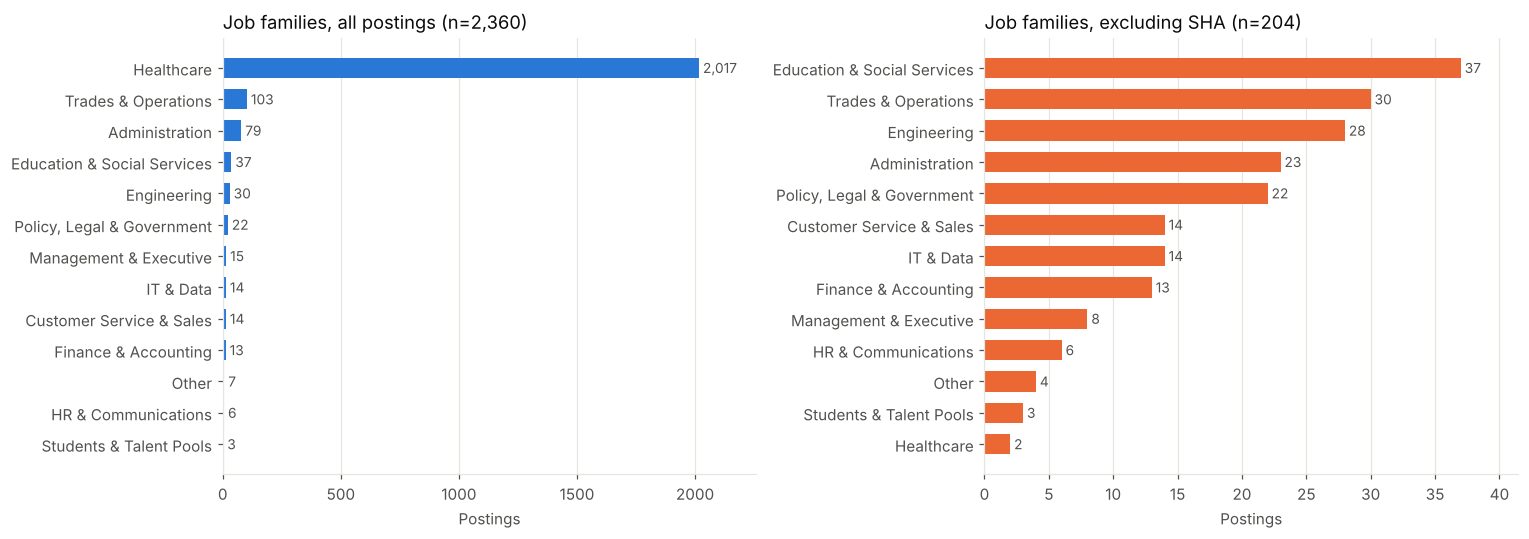

In [ ]:
fam_all = df["Job_Family"].value_counts()
fam_other = df.loc[df["Source"].ne(SHA), "Job_Family"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
barh(fam_all, f"Job families, all postings (n={len(df):,})", ax=axes[0])
barh(fam_other, f"Job families, excluding SHA (n={fam_other.sum():,})", color=ORANGE, ax=axes[1])
plt.tight_layout(); plt.show()

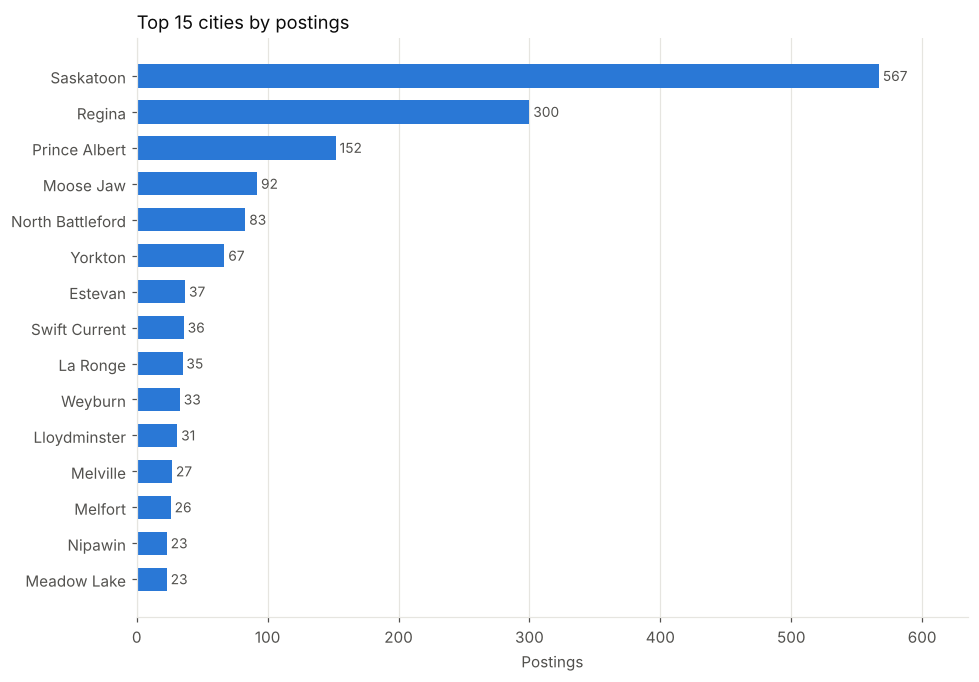

146 distinct cities. Regina + Saskatoon = 37% of postings with a city; top 10 cities = 60%.


In [ ]:
top_cities = df["City"].value_counts().head(15)
ax = barh(top_cities, "Top 15 cities by postings")
plt.tight_layout(); plt.show()

city_share = df["City"].value_counts(normalize=True).mul(100)
print(f"{df['City'].nunique()} distinct cities. Regina + Saskatoon = "
      f"{city_share.reindex(['Regina', 'Saskatoon']).sum():.0f}% of postings with a city; "
      f"top 10 cities = {city_share.head(10).sum():.0f}%.")

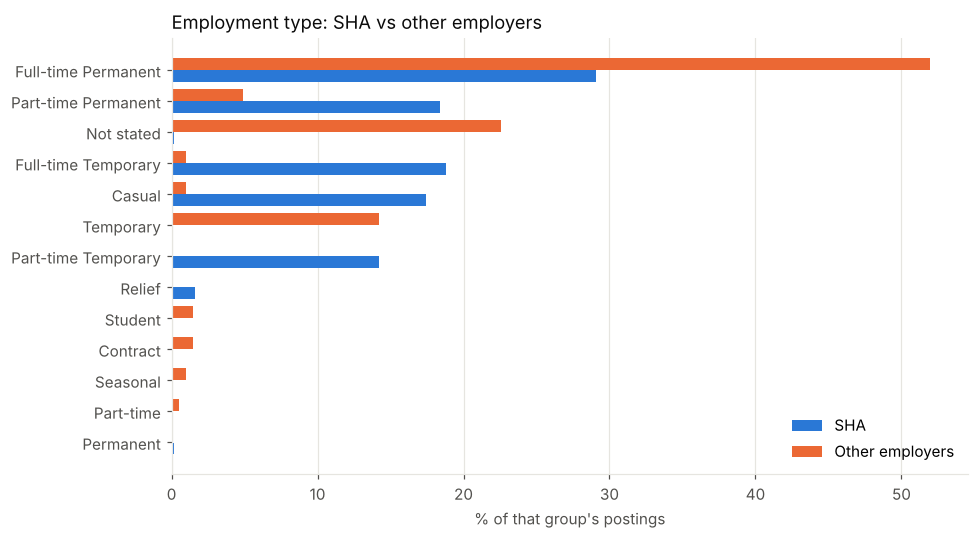

FTE (share of a full-time position), where stated:


,count,mean,50%
Source,,,
Saskatchewan Health Authority,2132.0,0.68,0.83


In [ ]:
emp = pd.crosstab(df["Employment_Type_Standardized"].fillna("Not stated"),
                  np.where(df["Source"].eq(SHA), "SHA", "Other employers"), normalize="columns").mul(100)
emp = emp.loc[emp.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(emp))
ax.barh(y - 0.2, emp["SHA"], height=0.38, color=BLUE, label="SHA")
ax.barh(y + 0.2, emp["Other employers"], height=0.38, color=ORANGE, label="Other employers")
ax.set_yticks(y, emp.index)
ax.set_xlabel("% of that group's postings")
ax.set_title("Employment type: SHA vs other employers")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

print("FTE (share of a full-time position), where stated:")
display(df.groupby("Source")["FTE"].describe()[["count", "mean", "50%"]].round(2).dropna())

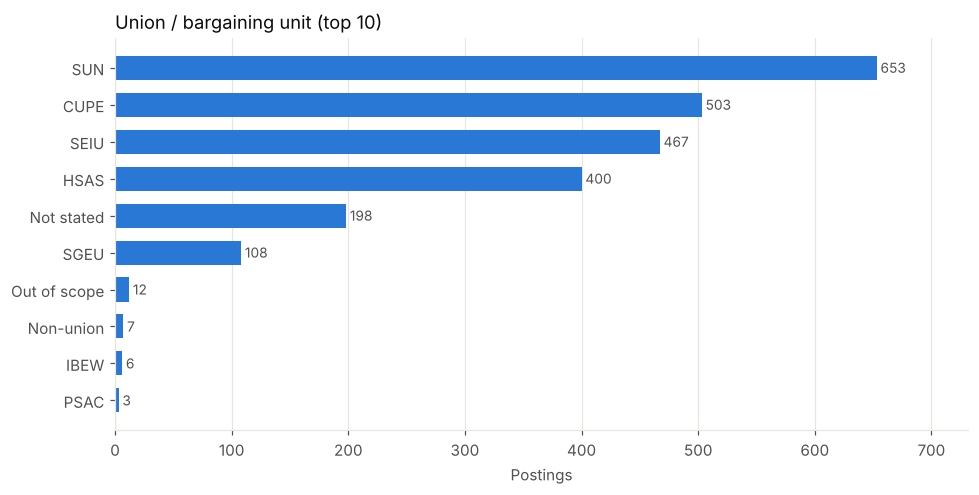

In [ ]:
union = df["Union_Clean"].fillna("Not stated").value_counts()
ax = barh(union.head(10), "Union / bargaining unit (top 10)")
plt.tight_layout(); plt.show()

## 5. Salary
All pay is compared as the **hourly-equivalent midpoint** of the posted range.

Many postings repeat the same pay band (one SHA band, *Nurse A*, covers hundreds of postings), so per-posting counts
mostly measure how many identical jobs are listed. Each distribution is therefore also shown **per distinct pay range**
(one point per employer + title + salary text).

Postings with a usable salary: 2,325 of 2,360 (99%)
Distinct pay ranges: 383
Top 10 salary strings cover 62% of postings with pay



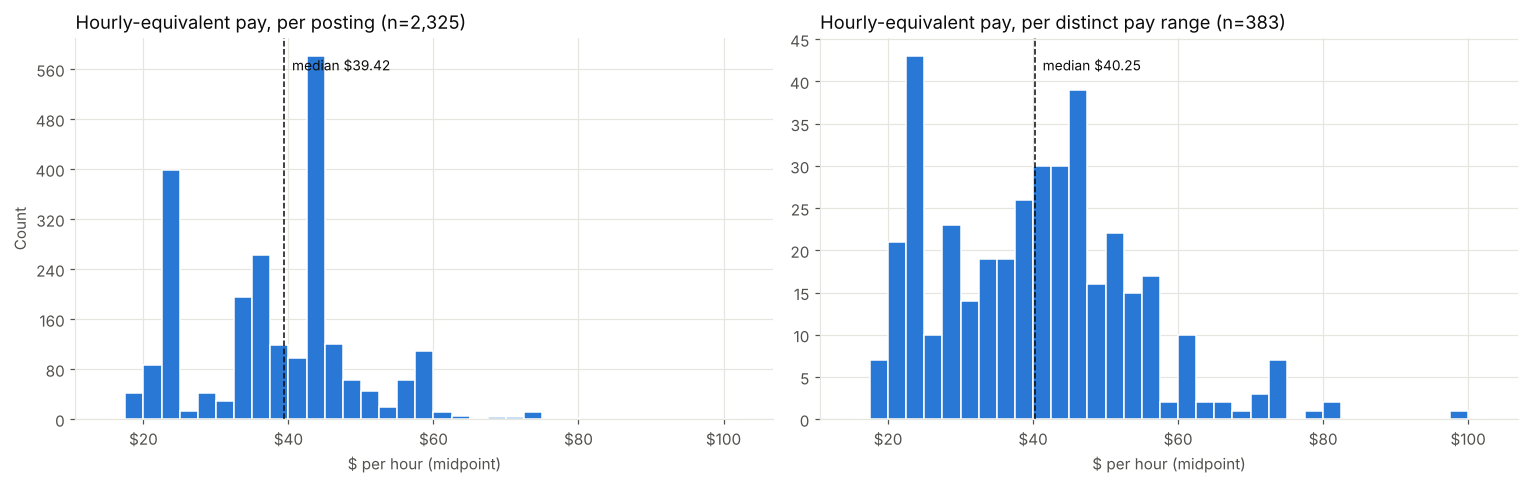

,per posting,per distinct range
count,2325.00,383.00
mean,38.72,40.74
std,11.32,14.58
min,18.26,18.26
25%,29.64,29.30
50%,39.42,40.25
75%,44.32,48.18
max,151.32,151.32


In [ ]:
pay = df[df["Hourly_Equiv"].notna()].copy()
distinct = pay.drop_duplicates(subset=["Source", "Job_Title", "Salary_Range"])
print(f"Postings with a usable salary: {len(pay):,} of {len(df):,} ({len(pay) / len(df):.0%})")
print(f"Distinct pay ranges: {len(distinct):,}")

top10 = pay["Salary_Range"].value_counts().head(10)
print(f"Top 10 salary strings cover {top10.sum() / len(pay):.0%} of postings with pay\n")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharex=True)
for ax, data, label in [(axes[0], pay, "per posting"), (axes[1], distinct, "per distinct pay range")]:
    ax.hist(data["Hourly_Equiv"], bins=np.arange(15, 105, 2.5), color=BLUE, edgecolor="white", linewidth=1)
    ax.axvline(data["Hourly_Equiv"].median(), color=INK, linestyle="--", linewidth=1)
    ax.text(data["Hourly_Equiv"].median(), ax.get_ylim()[1] * 0.95,
            f"  median ${data['Hourly_Equiv'].median():.2f}", color=INK, fontsize=9, va="top")
    ax.set_title(f"Hourly-equivalent pay, {label} (n={len(data):,})")
    ax.set_xlabel("$ per hour (midpoint)")
    ax.xaxis.set_major_formatter(dollars)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].set_ylabel("Count")
plt.tight_layout(); plt.show()

display(pd.DataFrame({"per posting": pay["Hourly_Equiv"].describe(),
                      "per distinct range": distinct["Hourly_Equiv"].describe()}).round(2))

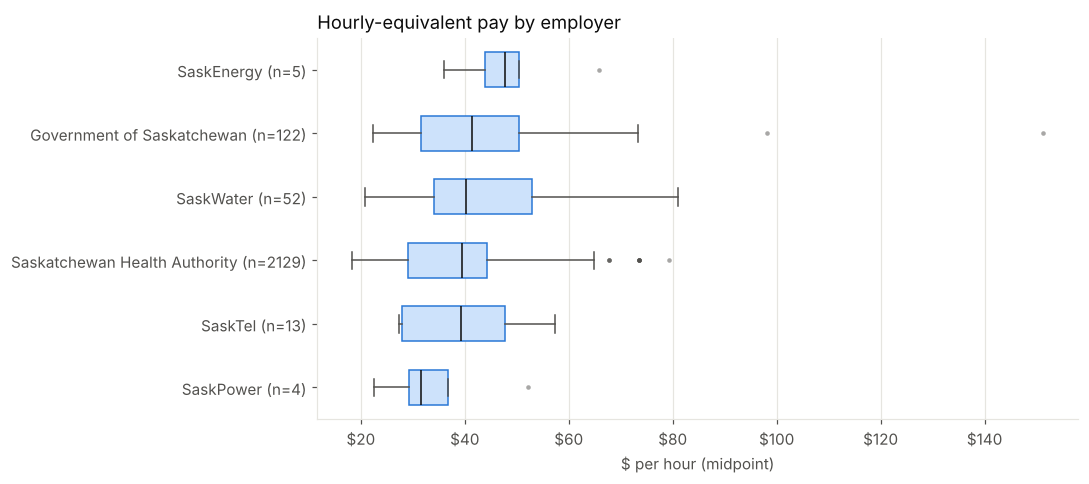

,postings,median,q25,q75,min,max
Source,,,,,,
SaskEnergy,5,47.76,43.88,50.52,35.98,65.78
Government of Saskatchewan,122,41.35,31.64,50.40,22.35,151.32
SaskWater,52,40.27,34.11,53.00,20.79,80.95
Saskatchewan Health Authority,2129,39.42,28.99,44.32,18.26,79.34
SaskTel,13,39.28,27.97,47.70,27.42,57.39
SaskPower,4,31.53,29.28,36.68,22.55,52.15


In [ ]:
order = pay.groupby("Source")["Hourly_Equiv"].median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot([pay.loc[pay["Source"].eq(s), "Hourly_Equiv"] for s in order], vert=False, widths=0.55,
           patch_artist=True, boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE),
           medianprops=dict(color=INK), whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=MUTED, markeredgecolor="none", alpha=0.5))
ax.set_yticks(range(1, len(order) + 1),
              [f"{s} (n={pay['Source'].eq(s).sum()})" for s in order])
ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel("$ per hour (midpoint)")
ax.set_title("Hourly-equivalent pay by employer")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

display(pay.groupby("Source")["Hourly_Equiv"]
           .agg(postings="count", median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75),
                min="min", max="max")
           .sort_values("median", ascending=False).round(2))

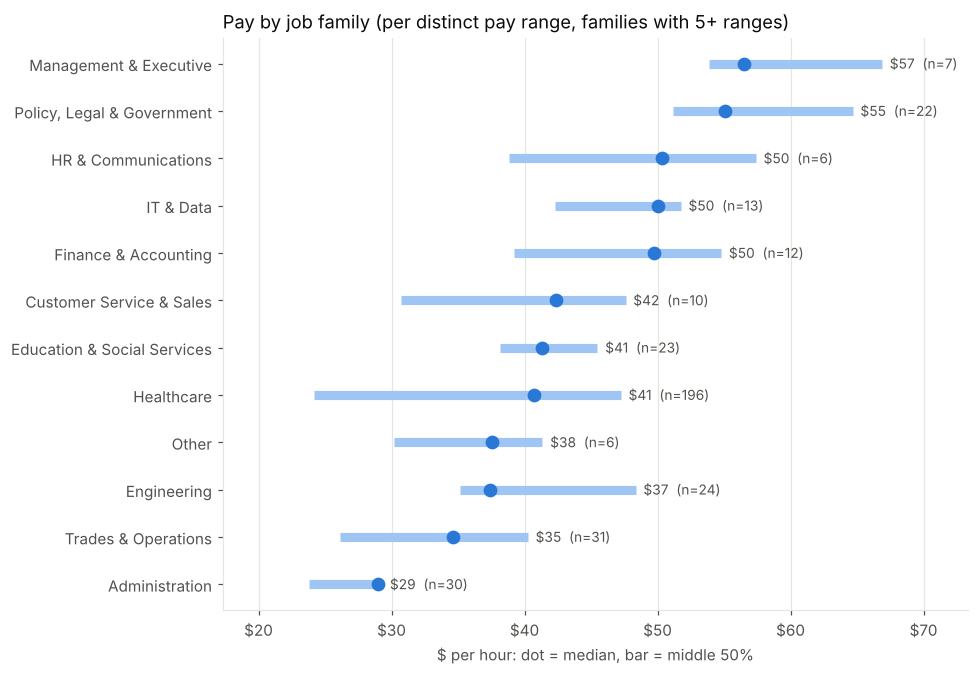

In [ ]:
fam_pay = (distinct.groupby("Job_Family")["Hourly_Equiv"]
             .agg(pay_ranges="count", median="median", q25=lambda s: s.quantile(.25), q75=lambda s: s.quantile(.75))
             .query("pay_ranges >= 5").sort_values("median"))

fig, ax = plt.subplots(figsize=(9, 0.42 * len(fam_pay) + 1.2))
y = np.arange(len(fam_pay))
ax.hlines(y, fam_pay["q25"], fam_pay["q75"], color="#9ec5f4", linewidth=6)
ax.plot(fam_pay["median"], y, "o", color=BLUE, markersize=8)
for yi, (m, n) in enumerate(zip(fam_pay["median"], fam_pay["pay_ranges"])):
    ax.text(fam_pay["q75"].iloc[yi], yi, f"  ${m:.0f}  (n={n})", va="center", fontsize=9, color=MUTED)
ax.set_yticks(y, fam_pay.index)
ax.xaxis.set_major_formatter(dollars)
ax.set_xlabel("$ per hour: dot = median, bar = middle 50%")
ax.set_title("Pay by job family (per distinct pay range, families with 5+ ranges)")
ax.grid(axis="y", visible=False)
ax.margins(x=0.15)
plt.tight_layout(); plt.show()

In [ ]:
cols = ["Source", "Job_Title", "Salary_Range", "Final_Unit", "Hourly_Equiv"]
print("Highest-paid distinct pay ranges:")
display(distinct.nlargest(10, "Hourly_Equiv")[cols].round(2))
print("Lowest-paid distinct pay ranges:")
display(distinct.nsmallest(10, "Hourly_Equiv")[cols].round(2))

Highest-paid distinct pay ranges:


,Source,Job_Title,Salary_Range,Final_Unit,Hourly_Equiv
115,Government of Saskatchewan,Deputy Chief Medical Health Officer,22808.0 - 29649.0,Monthly,151.32
107,Government of Saskatchewan,Public Guardian and Trustee,14797.99 - 19242.85,Monthly,98.19
2321,SaskWater,"Vice-President, Finance & Corporate Services","$149,667 to $187,084 annually plus 4% Salary H...",Annual,80.95
2322,SaskWater,"Vice-President, Strategic Growth & Customer En...","$149,667 to $187,084 annually plus 4% Salary H...",Annual,80.95
1636,Saskatchewan Health Authority,Psychologist PhD Senior,Pay Band Psychologist - PhD Senior $71.482 to ...,Hourly,79.34
1058,Saskatchewan Health Authority,Psychologist PhD,Pay Band Psychologist - PhD $66.185 to $80.744,Hourly,73.46
54,Government of Saskatchewan,Legal Counsel,"$8,523.50 - $16,861.96 monthly",Monthly,73.23
62,Government of Saskatchewan,Crown Prosecutor,8523.50-16861.96,Monthly,73.23
113,Government of Saskatchewan,Legal Counsel,"8,523.50 - 16,861.96",Monthly,73.23
118,Government of Saskatchewan,Crown Counsel,"$8,523.50 - $16,861.96 monthly",Monthly,73.23


Lowest-paid distinct pay ranges:


,Source,Job_Title,Salary_Range,Final_Unit,Hourly_Equiv
1198,Saskatchewan Health Authority,Client Attendant,Pay Band 3 $17.630 to $18.900 (3 step range),Hourly,18.26
367,Saskatchewan Health Authority,Print Shop Worker,Pay Band 4 $18.270 to $19.570 (3 step range),Hourly,18.92
173,Saskatchewan Health Authority,Environmental Services Worker,Pay Band 5 $18.890 to $20.240 (3 step range),Hourly,19.56
234,Saskatchewan Health Authority,Environmental & Laundry Services Worker,Pay Band 5 $18.890 to $20.240 (3 step range),Hourly,19.56
423,Saskatchewan Health Authority,Porter,Pay Band 5 $18.890 to $20.240 (3 step range),Hourly,19.56
634,Saskatchewan Health Authority,Laundry Services Worker,Pay Band 5 $18.890 to $20.240 (3 step range),Hourly,19.56
1195,Saskatchewan Health Authority,Entrance Attendant,Pay Band 5 $18.890 to $20.240 (3 step range),Hourly,19.56
127,Saskatchewan Health Authority,Food Services Worker,Pay Band 6 $19.520 to $20.880 (3 step range),Hourly,20.20
379,Saskatchewan Health Authority,Food Services Worker,"Pay Band 6, $19.52 to $20.88 (3 step range)",Hourly,20.20
412,Saskatchewan Health Authority,Food Services Worker,Pay Band 6 $ 19.520 to $20.880 (3 step range),Hourly,20.20


## 6. Time
- **Posting age**: days between the posting date and the collection date, for open postings.
  Old open postings are usually *standing* or *continuous* competitions that stay listed until filled.
- **Application window**: days between posting and closing date (where a closing date exists).

In [ ]:
open_now = df[df["Status"].eq("Open")].copy()
open_now["Posting_Age_Days"] = (open_now["Collection_Date"] - open_now["Posting_Date"]).dt.days
df["Window_Days"] = (df["Closing_Date"] - df["Posting_Date"]).dt.days

age_bins = [-1, 7, 30, 90, 365, 10_000]
age_labels = ["0-7 days", "8-30 days", "31-90 days", "91-365 days", "Over a year"]
open_now["Age_Band"] = pd.cut(open_now["Posting_Age_Days"], age_bins, labels=age_labels)

age_table = pd.crosstab(open_now["Source"], open_now["Age_Band"], normalize="index").mul(100).round(0)
display(age_table.style.format("{:.0f}%").background_gradient(cmap="Blues", axis=None))

summary_time = pd.DataFrame({
    "Open postings": open_now.groupby("Source").size(),
    "Median age (days)": open_now.groupby("Source")["Posting_Age_Days"].median(),
    "Has closing date %": df.groupby("Source")["Closing_Date"].apply(lambda s: s.notna().mean() * 100).round(0),
    "Median window (days)": df.groupby("Source")["Window_Days"].median(),
}).sort_values("Open postings", ascending=False)
summary_time

Age_Band,0-7 days,8-30 days,31-90 days,91-365 days,Over a year
Source,,,,,
Government of Saskatchewan,54%,46%,0%,0%,0%
SaskEnergy,60%,40%,0%,0%,0%
SaskPower,45%,55%,0%,0%,0%
SaskTel,50%,50%,0%,0%,0%
Saskatchewan Health Authority,46%,21%,19%,14%,1%


,Open postings,Median age (days),Has closing date %,Median window (days)
Source,,,,
Saskatchewan Health Authority,2156.0,9.0,42.0,8.0
Government of Saskatchewan,122.0,5.0,100.0,13.0
SaskTel,14.0,6.0,79.0,15.0
SaskPower,11.0,10.0,100.0,29.0
SaskEnergy,5.0,3.0,100.0,15.0
SaskWater,NaN,NaN,100.0,14.0


SHA open postings with no closing date: 58%
Median age, SHA with a closing date:    3 days
Median age, SHA without a closing date: 43 days


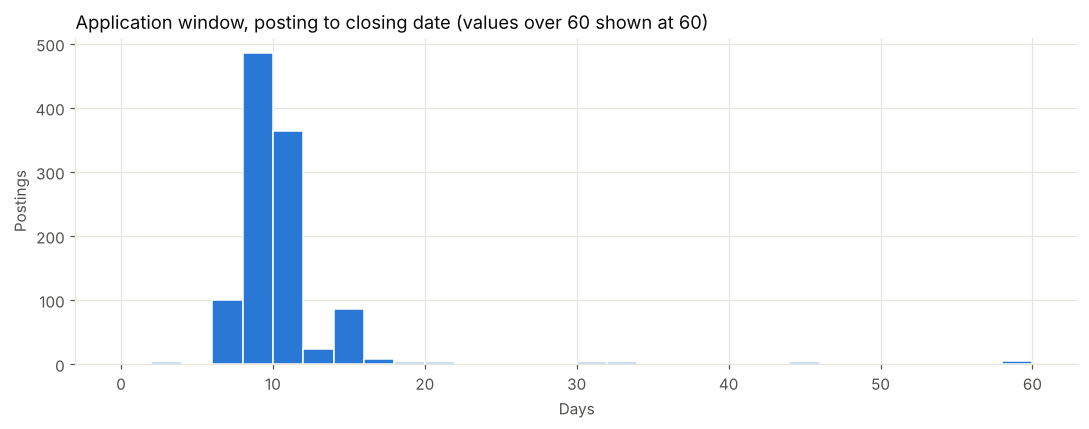

In [ ]:
sha_open = open_now[open_now["Source"].eq(SHA)]
no_close = sha_open["Closing_Date"].isna()
print(f"SHA open postings with no closing date: {no_close.mean():.0%}")
print(f"Median age, SHA with a closing date:    {sha_open.loc[~no_close, 'Posting_Age_Days'].median():.0f} days")
print(f"Median age, SHA without a closing date: {sha_open.loc[no_close, 'Posting_Age_Days'].median():.0f} days")

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(df["Window_Days"].dropna().clip(upper=60), bins=np.arange(0, 62, 2), color=BLUE, edgecolor="white")
ax.set_title("Application window, posting to closing date (values over 60 shown at 60)")
ax.set_xlabel("Days")
ax.set_ylabel("Postings")
plt.tight_layout(); plt.show()

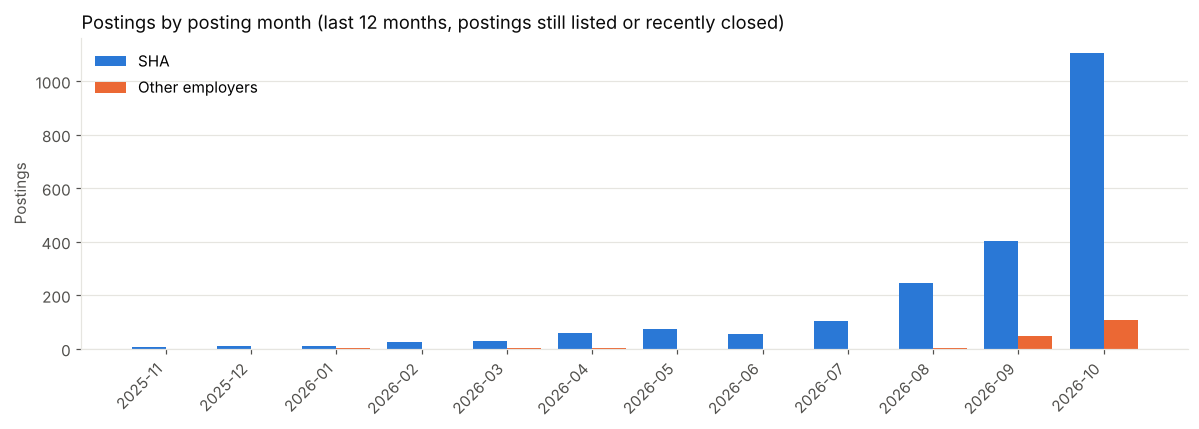

Postings dated before 2025-11: 62


In [ ]:
monthly = (df.assign(Month=df["Posting_Date"].dt.to_period("M"),
                     Group=np.where(df["Source"].eq(SHA), "SHA", "Other employers"))
             .groupby(["Month", "Group"]).size().unstack(fill_value=0))
recent = monthly.loc[monthly.index >= monthly.index.max() - 11]

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(recent))
ax.bar(x - 0.2, recent.get("SHA", 0), width=0.4, color=BLUE, label="SHA")
ax.bar(x + 0.2, recent.get("Other employers", 0), width=0.4, color=ORANGE, label="Other employers")
ax.set_xticks(x, [str(p) for p in recent.index], rotation=45, ha="right")
ax.set_ylabel("Postings")
ax.set_title("Postings by posting month (last 12 months, postings still listed or recently closed)")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"Postings dated before {recent.index.min()}: {int(monthly.loc[monthly.index < recent.index.min()].sum().sum())}")

**Read with care:** this is a snapshot of what was *listed* on the collection day plus postings closed since tracking began,
not a record of all hiring. The month chart is skewed to recent months because older postings have mostly closed and dropped off.
A real hiring-over-time trend needs the daily history that the GitHub Action builds up in MongoDB (`first_seen` / `closed_date`).

## 7. SHA vs other employers

In [ ]:
def profile(g: pd.DataFrame) -> pd.Series:
    p = g[g["Hourly_Equiv"].notna()]
    return pd.Series({
        "Postings": len(g),
        "Distinct titles": g["Job_Title"].nunique(),
        "Cities": g["City"].nunique(),
        "Full-time %": g["Employment_Type_Standardized"].str.startswith("Full-time", na=False).mean() * 100,
        "Permanent %": g["Employment_Type_Standardized"].str.contains("Permanent", na=False).mean() * 100,
        "Casual / relief %": g["Employment_Type_Standardized"].isin(["Casual", "Relief"]).mean() * 100,
        "Union stated %": g["Union_Clean"].notna().mean() * 100,
        "Has salary %": g["Hourly_Equiv"].notna().mean() * 100,
        "Median $/hour": p["Hourly_Equiv"].median(),
        "Has closing date %": g["Closing_Date"].notna().mean() * 100,
    })


comparison = pd.DataFrame({
    "SHA": profile(df[df["Source"].eq(SHA)]),
    "Other employers": profile(df[df["Source"].ne(SHA)]),
    "All": profile(df),
}).round(1)
comparison

,SHA,Other employers,All
Postings,2156.0,204.0,2360.0
Distinct titles,213.0,150.0,362.0
Cities,140.0,27.0,146.0
Full-time %,47.9,52.9,48.3
Permanent %,47.6,56.9,48.4
Casual / relief %,19.1,1.0,17.5
Union stated %,99.8,5.4,91.6
Has salary %,98.7,96.1,98.5
Median $/hour,39.4,41.3,39.4
Has closing date %,41.7,98.5,46.6


## 8. Key findings

In [ ]:
# Headline numbers for the write-up (recomputed on every run)
sha_share = df["Source"].eq(SHA).mean()
print(f"- {len(df):,} postings from {df['Source'].nunique()} employers; SHA = {sha_share:.0%}.")
print(f"- Largest job family: {fam_all.index[0]} ({fam_all.iloc[0] / len(df):.0%}); "
      f"outside SHA: {fam_other.index[0]} ({fam_other.iloc[0] / fam_other.sum():.0%}).")
print(f"- Median pay: ${pay['Hourly_Equiv'].median():.2f}/h per posting, "
      f"${distinct['Hourly_Equiv'].median():.2f}/h per distinct pay range.")
print(f"- Top 10 salary strings = {top10.sum() / len(pay):.0%} of postings with pay.")
print(f"- Salary units stated on the posting: {df['Unit_Source'].eq('Stated').sum()} of {df['Salary_Mid'].notna().sum()} postings with pay.")
print(f"- {open_now['Posting_Age_Days'].gt(90).mean():.0%} of open postings are over 90 days old.")

- 2,360 postings from 6 employers; SHA = 91%.
- Largest job family: Healthcare (85%); outside SHA: Education & Social Services (18%).
- Median pay: $39.42/h per posting, $40.25/h per distinct pay range.
- Top 10 salary strings = 62% of postings with pay.
- Salary units stated on the posting: 57 of 2325 postings with pay.
- 14% of open postings are over 90 days old.


*Written from the 10 Oct 2026 snapshot; the cell above recomputes the headline numbers when the data is refreshed.*

**1. One employer dominates the data.** SHA is 2,156 of 2,360 postings (91%), and healthcare is 85% of all postings.
Any "overall" figure is effectively an SHA figure, so results should be reported for SHA and for the other employers separately.
Outside SHA, demand is spread out: Education & Social Services (37), Trades & Operations (30), Engineering (28),
Administration (23) and Policy, Legal & Government (22).

**2. Jobs are spread across the province, mostly through SHA.** Saskatoon (567) and Regina (300) hold 37% of postings that
list a city, but postings come from 146 places. SHA posts in 140 of them; all other employers together post in 27.

**3. Employment terms differ.** About 48% of SHA postings are full-time and 19% are casual or relief. Other employers are
53% full-time and 57% permanent, with almost no casual work, though 22% of their postings don't state a type.

**4. Pay clusters on a few bands.** The median is **$39.42/h** per posting (about $82,000 a year at 2,080 hours) and
$40.25/h per distinct pay range. The top 10 salary strings cover 62% of postings (Nurse A alone is 451), which is why the
per-posting histogram is spiky. Pay runs from $18.26/h (SHA Client Attendant) to $151/h (GoS Deputy Chief Medical Health Officer).
By job family, Administration is lowest (median $29/h) and Management & Executive and Policy, Legal & Government are highest
($55-57/h). Employer medians sit within $39-48/h, except SaskPower, which has only 4 postings with pay.

**5. Salary units are mostly guessed, but the guesses hold up.** Only 57 of 2,325 postings with pay state their unit.
2,267 rely on the scraper's guess. Every guess passes the plausibility check, and guessed hourly pay falls in the same
range as stated hourly pay. One SaskWater posting with no unit was resolved to monthly by its size.

**6. SHA keeps standing competitions open.** 58% of SHA's open postings have no closing date. These are a median of
43 days old, against 3 days for SHA postings that do have one. 14% of all open postings are over 90 days old.
Application windows are short: a median of 8 days at SHA, 13 at GoS, about 15 at the crown corporations and 29 at SaskPower.

**Limitations**
- One day's listings plus closed SaskWater postings, not a full hiring record. Trends need the daily MongoDB history.
- The crown corporations are tiny samples (4-52 postings), so their medians are indicative only.
- The crown corporations don't publish union information, so "Union stated %" is not a unionization rate.
- `Job_Family` is keyword-based. Check the crosstab in section 3 before quoting family-level numbers.